## **DATA 620 - Week 8 Assignment**
## High Frequency Words: Harry Potter and the Philosopher's Stone
## Brandon Chanderban

## Introduction

For the purpose of this assignment, I selected a dialogue corpus in the form of *Harry Potter and the Philosopher's Stone* (2001), the first installment of the Harry Potter film series. Having been a longtime fan of the Harry Potter universe, I thought it would be interesting to examine the movie's dialogue from a text-mining perspective, utilizing a publicly available dataset containing dialogue attributed to its individual characters.

The principal objective of this analysis is to examine word-frequency patterns within the corpus by identifying its total and unique word counts, determining the number of words accounting for half of all occurrences, and analyzing the 200 most frequently used words. The resulting distribution will then be evaluated against Zipf's law, with consideration given to how the movie's vocabulary may differ from that of the general English-language corpora.


## Dataset Import and Initial Inspection

The dataset utilized in this analysis was obtained from the publicly available Harry Potter Movies Dataset on GitHub. Specifically, the hp1.csv file contains dialogue from Harry Potter and the Philosopher's Stone (2001), organized by movie, chapter, character, and dialogue. A copy of the dataset has been stored within my personal GitHub repository to support reproducibility.

The dataset will first be imported using pandas, after which its dimensions, variables, and initial observations will be examined before proceeding with the text preprocessing.

In [1]:
# Import the required libraries.
import pandas as pd
import re
import nltk
from nltk.corpus import stopwords
from nltk.probability import FreqDist
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
from wordcloud import WordCloud, STOPWORDS
from PIL import Image, ImageDraw

# Import the Harry Potter dialogue dataset from GitHub.
url = ("https://raw.githubusercontent.com/bkchanderban/CUNY_SPS/refs/heads/main/DATA620/Week_8_Assignment/hp1.csv")

hp_dialogue = pd.read_csv(url)

# Examine the dataset's dimensions.
print("The dataset's dimensions are:", hp_dialogue.shape)

# Display the column names.
print("\nThe dataset's columns are as follows:")
print(hp_dialogue.columns.tolist())

# Examine the first five observations.
print("\nThe first five observations are:")
display(hp_dialogue.head())

The dataset's dimensions are: (885, 4)

The dataset's columns are as follows:
['movie', 'chapter', 'character', 'dialog']

The first five observations are:


,movie,chapter,character,dialog
0,Harry Potter and the Philosopher's Stone,Doorstep Delivery,Albus Dumbledore,I should have known that you would be here...P...
1,Harry Potter and the Philosopher's Stone,Doorstep Delivery,Minerva McGonagall,"Good evening, Professor Dumbledore. Are the ru..."
2,Harry Potter and the Philosopher's Stone,Doorstep Delivery,Albus Dumbledore,"I'm afraid so, Professor. The good, and the bad."
3,Harry Potter and the Philosopher's Stone,Doorstep Delivery,Minerva McGonagall,And the boy?
4,Harry Potter and the Philosopher's Stone,Doorstep Delivery,Albus Dumbledore,Hagrid is bringing him.


The dataset was successfully imported and contains 885 observations across four variables (movie, chapter, character, and dialog). Each represents a dialogue entry attributed to a particular character and chapter of the film. For the purposes of this assignment, the dialog variable will serve as the primary corpus, whilst the remaining variables provide contextual information and will be excluded from the word-frequency calculations.

## Assessing the Corpus

In [2]:
# Check for missing values in each variable.
print("Missing values in each variable/column:")
print(hp_dialogue.isnull().sum())

# Check for duplicate observations.
print("\nThe number of duplicate observations is as follows:")
print(hp_dialogue.duplicated().sum())

# Examine all observations belonging to duplicate groups.
duplicate_rows = hp_dialogue[
    hp_dialogue.duplicated(keep=False)
]

# Display the duplicate observations with their original indices.
print("Observations belonging to duplicate groups:")
display(duplicate_rows)

# Examine the data types.
print("\nThe data types are:")
print(hp_dialogue.dtypes)

Missing values in each variable/column:
movie        0
chapter      0
character    0
dialog       0
dtype: int64

The number of duplicate observations is as follows:
6
Observations belonging to duplicate groups:


,movie,chapter,character,dialog
273,Harry Potter and the Philosopher's Stone,Nick and Other Residents,Ron Weasley,Ahh!
283,Harry Potter and the Philosopher's Stone,Nick and Other Residents,Ron Weasley,Ahh!
304,Harry Potter and the Philosopher's Stone,Potions and Parcels,Harry Potter,"I don't know, sir."
306,Harry Potter and the Philosopher's Stone,Potions and Parcels,Harry Potter,"I don't know, sir."
335,Harry Potter and the Philosopher's Stone,New Seeker,Neville Longbottom,AHH!
341,Harry Potter and the Philosopher's Stone,New Seeker,Neville Longbottom,AHH!
591,Harry Potter and the Philosopher's Stone,The Mirror of Erised,Harry Potter,No.
593,Harry Potter and the Philosopher's Stone,The Mirror of Erised,Harry Potter,No.
608,Harry Potter and the Philosopher's Stone,Norbert,Harry Potter,Malfoy.
657,Harry Potter and the Philosopher's Stone,Norbert,Harry Potter,Malfoy.



The data types are:
movie        object
chapter      object
character    object
dialog       object
dtype: object


The initial inspection of the dataset revealed no missing values across its four variables, although six duplicated observations were identified. Upon further examination, these consisted primarily of short statements and exclamations repeated by the same characters within individual chapters. Given that such repetitions may represent legitimate instances of dialogue rather than erroneous records, all 885 observations were retained to preserve the word frequencies represented in the original corpus.

## Corpus Preparation and Tokenization

To prepare the dialogue corpus for analysis, the text will be converted to lowercase and tokenized into individual words, with punctuation marks and nonword symbols being stripped/excluded. Apostrophes within contractions will be retained, whilst common stopwords and repeated word occurrences will remain in the corpus, as these are relevant to the examination of word-frequency distributions and Zipf's law.

Only the dialog variable will be utilized, ensuring that character names and chapter titles included as dataset metadata do not influence the resulting word counts.

In [3]:
# Combine all dialogue observations into one text corpus.
corpus = " ".join(hp_dialogue["dialog"].astype(str))

# Convert the text to lowercase.
corpus = corpus.lower()

# Extract words, retaining apostrophes within contractions.
words = re.findall(r"[a-z]+(?:['’][a-z]+)*", corpus)

# Generate the word-frequency distribution.
word_freq = FreqDist(words)

# Examine the total number of words and unique words.
print("The total number of words in the corpus is:", len(words))
print("The number of unique words in the corpus is:", len(word_freq))

# Display the ten most frequently occurring words.
print("\nThe ten most frequently occurring words are:")
display(word_freq.most_common(10))

The total number of words in the corpus is: 9778
The number of unique words in the corpus is: 1775

The ten most frequently occurring words are:


[('you', 326),
 ('the', 288),
 ('to', 241),
 ('i', 227),
 ('a', 199),
 ('and', 150),
 ('it', 142),
 ('that', 125),
 ('of', 121),
 ('is', 106)]

Following the tokenization of the dialogue corpus, a total of 9,778 word occurrences were identified, comprising 1,775 unique words. For this analysis, unique words were defined as distinct lowercase alphabetical tokens, with internal apostrophes retained in contractions and punctuation excluded. Common stopwords and repeated word occurrences were preserved to maintain the original frequency distribution of the dialogue.

An initial examination of the ten most frequently occurring words revealed that "you" appeared most often, with 326 occurrences, followed by "the" (288), "to" (241), "i" (227), and "a" (199). The prominence of these common words is consistent with the conversational nature of the selected corpus.

## Cumulative Word Frequency Analysis

In [4]:
# Sort words from highest to lowest frequency.
sorted_words = word_freq.most_common()

# Determine the number of word occurrences representing 50% of the corpus.
half_corpus = len(words) * 0.50

# Initialize the cumulative frequency and unique word counter.
cumulative_frequency = 0
unique_word_counter = 0

# Count how many of the most frequent words account for half of the corpus.
for word, frequency in sorted_words:
    cumulative_frequency += frequency
    unique_word_counter += 1

    if cumulative_frequency >= half_corpus:
        break

# Display the results.
print("The total word occurrence is:", len(words))
print("As such, half of the corpus is:", int(half_corpus))
print("The number of unique words that account for half of the corpus is:", unique_word_counter)
print(f"Therefore, {round(unique_word_counter / len(word_freq) * 100, 2)}% of the corpus's unique vocabulary accounts for more than half of its dialogue.")
print("The cumulative word occurrences is:", cumulative_frequency)
print("The exact % of the corpus covered is:", round(cumulative_frequency / len(words) * 100, 2), "%")

The total word occurrence is: 9778
As such, half of the corpus is: 4889
The number of unique words that account for half of the corpus is: 74
Therefore, 4.17% of the corpus's unique vocabulary accounts for more than half of its dialogue.
The cumulative word occurrences is: 4899
The exact % of the corpus covered is: 50.1 %


The cumulative word-frequency analysis revealed that only 74 of the 1,775 unique words were required to account for at least half of all word occurrences within the corpus. Specifically, these 74 words collectively appeared 4,899 times, representing approximately 50.10% of the 9,778 total word occurrences. This indicates that just 4.17% of the corpus's unique vocabulary accounts for more than half of its dialogue, demonstrating the substantial concentration of word usage amongst a relatively small number of frequently occurring terms.

## Identifying the 200 Most Frequent Words

In [5]:
# Extract the 200 most frequent words.
top_200 = word_freq.most_common(200)

# Convert the top 200 words to a pandas DataFrame.
top_200_df = pd.DataFrame(top_200, columns=["Word", "Frequency"])

# Add a ranking column.
top_200_df.insert(0, "Rank", range(1, len(top_200_df) + 1))

# Display the 200 highest-frequency words.
print("The 200 most frequently occurring words are:")
display(top_200_df)

The 200 most frequently occurring words are:


,Rank,Word,Frequency
0,1,you,326
1,2,the,288
2,3,to,241
3,4,i,227
4,5,a,199
...,...,...,...
195,196,longbottom,9
196,197,neville,9
197,198,seeker,9
198,199,blood,9


The 200 most frequently occurring words were extracted from the corpus and organized according to their respective frequencies. The results demonstrate a considerable difference between the highest- and lowest-ranked words, with "you" appearing 326 times, compared with eight occurrences for "trust" at rank 200. This provides an initial indication of the uneven distribution of word usage within the corpus, which will be examined further through relative-frequency analysis and Zipf's law.

## Relative Word Frequency Visualization

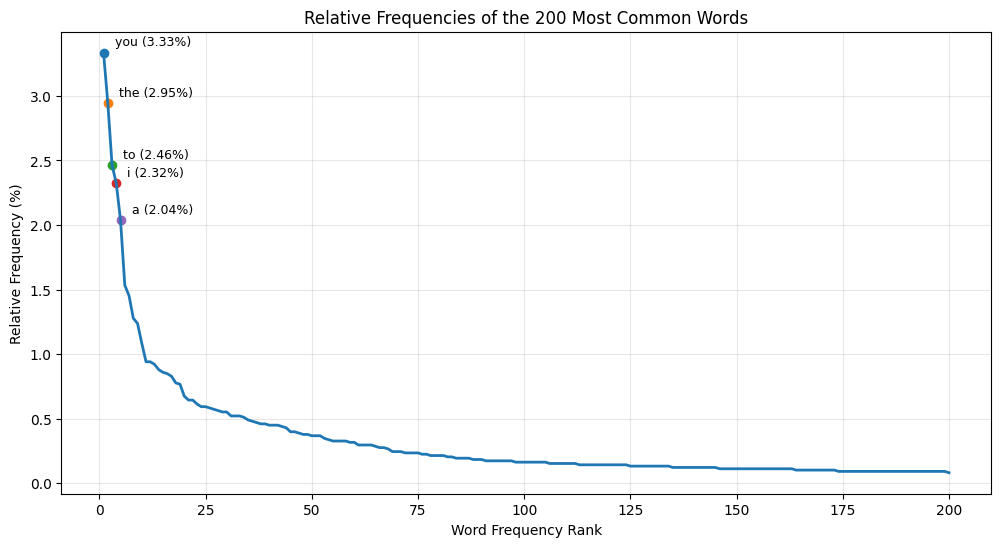

In [6]:
# Calculate the relative frequency of each word.
top_200_df["Relative Frequency"] = top_200_df["Frequency"] / len(words)

# Convert relative frequency to percentage for easier interpretation.
top_200_df["Relative Frequency (%)"] = top_200_df["Relative Frequency"] * 100

# Plot the Relative Frequency of the 200 highest-frequency words.
plt.figure(figsize=(12, 6))

plt.plot(
    top_200_df["Rank"],
    top_200_df["Relative Frequency (%)"],
    linewidth=2
)

plt.title("Relative Frequencies of the 200 Most Common Words")
plt.xlabel("Word Frequency Rank")
plt.ylabel("Relative Frequency (%)")
plt.grid(alpha=0.3)

# Add points and labels for the five most frequent words.
for _, row in top_200_df.head(5).iterrows():
    plt.scatter(row["Rank"], row["Relative Frequency (%)"])
    plt.annotate(
        f'{row["Word"]} ({row["Relative Frequency (%)"]:.2f}%)',
        (row["Rank"], row["Relative Frequency (%)"]),
        xytext=(8, 5),
        textcoords="offset points",
        fontsize=9
    )

plt.show()

The relative-frequency visualization demonstrates a pronounced decline in word frequency as the ranking progresses from the most commonly occurring words to those appearing less frequently. The highest-ranked word, "you", accounts for approximately 3.33% of all word occurrences, whilst the 200th-ranked word, "trust", accounts for approximately 0.08%. The distribution exhibits a steep initial decline followed by a gradual flattening, indicating that a relatively small number of words occur considerably more frequently than the remainder. This pattern provides an initial basis for examining whether the corpus follows Zipf's law.

## Zipf's Law - Rank-Frequency Analysis

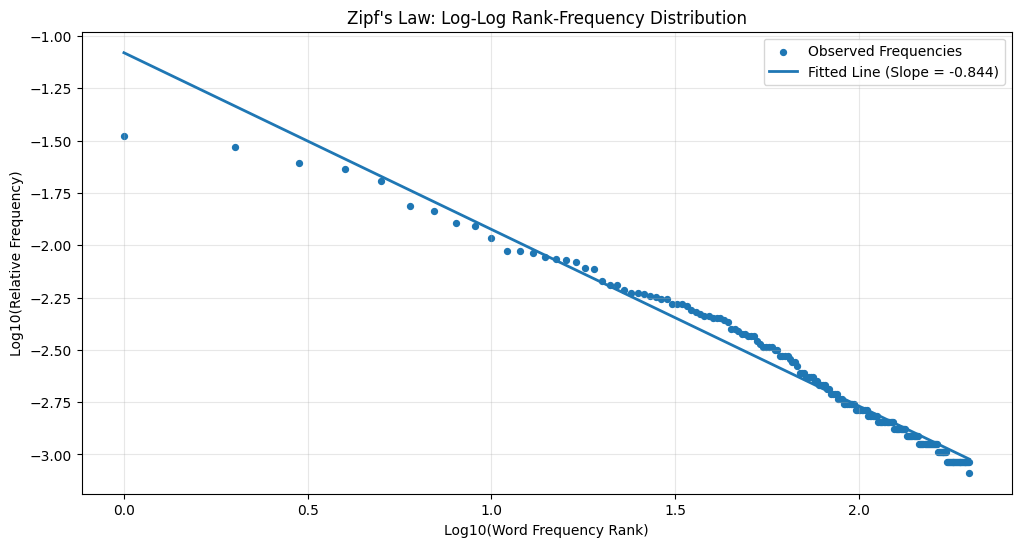

The estimated log-log slope is: -0.844
The estimated Zipf exponent is: 0.844


In [7]:
# Calculate the logarithms of word ranks and relative frequencies.
log_rank = np.log10(top_200_df["Rank"])
log_frequency = np.log10(top_200_df["Relative Frequency"])

# Fit a straight line to the log-log relationship.
slope, intercept = np.polyfit(log_rank, log_frequency, 1)

# Calculate the fitted values.
fitted_log_frequency = slope * log_rank + intercept

# Plot the observed word frequencies and fitted line.
plt.figure(figsize=(12, 6))

plt.scatter(log_rank, log_frequency, s=18, label="Observed Frequencies")

plt.plot(
    log_rank,
    fitted_log_frequency,
    linewidth=2,
    label=f"Fitted Line (Slope = {slope:.3f})"
)

plt.title("Zipf's Law: Log-Log Rank-Frequency Distribution")
plt.xlabel("Log10(Word Frequency Rank)")
plt.ylabel("Log10(Relative Frequency)")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

# Display the estimated Zipf exponent.
print("The estimated log-log slope is:", round(slope, 3))
print("The estimated Zipf exponent is:", round(-slope, 3))


The log-log rank-frequency analysis suggests that the observed word frequencies broadly follow Zipf's law, although some deviations from the classical relationship are evident. The fitted regression line produced a slope of approximately −0.844, corresponding to an estimated Zipf exponent of 0.844. Whilst this differs from the theoretical exponent of approximately 1, the observed frequencies generally exhibit a declining, approximately linear pattern on the logarithmic scale, suggesting that higher-ranked words occur substantially more frequently than lower-ranked words. However, some curvature and departures from the fitted line are apparent, indicating that the corpus does not adhere perfectly to the classical Zipf distribution. These findings should also be interpreted in light of the analysis being restricted to the 200 most frequently occurring words.

## Comparison with the General English-Language Corpus

In [8]:
# Import NLTK's English stopword list.

nltk.download("stopwords")

# Create a set of common English stopwords.
stop_words = set(stopwords.words("english"))

# Identify words among the top 200 that are not stopwords.
distinctive_words = top_200_df[
    ~top_200_df["Word"].isin(stop_words)
].copy()

# Display the remaining words with their original ranks and frequencies.
print("Top 200 words excluding common English stopwords:")
display(distinctive_words[["Rank", "Word", "Frequency"]])

Top 200 words excluding common English stopwords:


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


,Rank,Word,Frequency
10,11,harry,92
24,25,go,58
29,30,oh,54
32,33,know,51
36,37,one,46
...,...,...,...
195,196,longbottom,9
196,197,neville,9
197,198,seeker,9
198,199,blood,9


The filtered word-frequency results suggest that the dialogue corpus from Harry Potter and the Philosopher's Stone contains several distinctive vocabulary patterns that would likely differ from those of more general English-language corpora. Given the film's fictional setting, character names and magical terminology appear relatively frequently, with examples including "Harry" (92 occurrences), "Hogwarts" (23), "Gryffindor" (21), "Slytherin" (17), and "Quidditch" (11). In particular, "Harry" ranks 11th amongst all words in the corpus, demonstrating the prominence of character-specific vocabulary within the dialogue.

Nevertheless, the corpus also contains frequently occurring conversational words such as "go", "know", "well", and "see", alongside common grammatical words identified earlier, including "you", "the", and "to". As such, whilst the broader word-frequency distribution may resemble that of general English, particularly in its approximate alignment with Zipf's law, the prevalence of specific character names, fictional locations, and magical terminology reflects the film's distinctive narrative context. I would therefore expect the greatest differences to occur in the relative frequencies of individual content words, rather than in the general pattern of word-frequency concentration.

## Bonus Analysis: Word Cloud of Distinctive Harry Potter Vocabulary

As an additional exploratory step, a lightning bolt-shaped word cloud was generated to visualize prominent vocabulary within the dialogue corpus after removing common English stopwords and selected generic conversational terms. The resulting visualization highlights several character names and story-related expressions, including "Harry", "Potter", "Gryffindor", and "Hogwarts", alongside frequently occurring conversational words such as "think", "good", and "sorry". This provides a visual complement to the earlier frequency analysis, illustrating how the film's dialogue combines ordinary English vocabulary with terminology associated with its distinctive fictional setting.

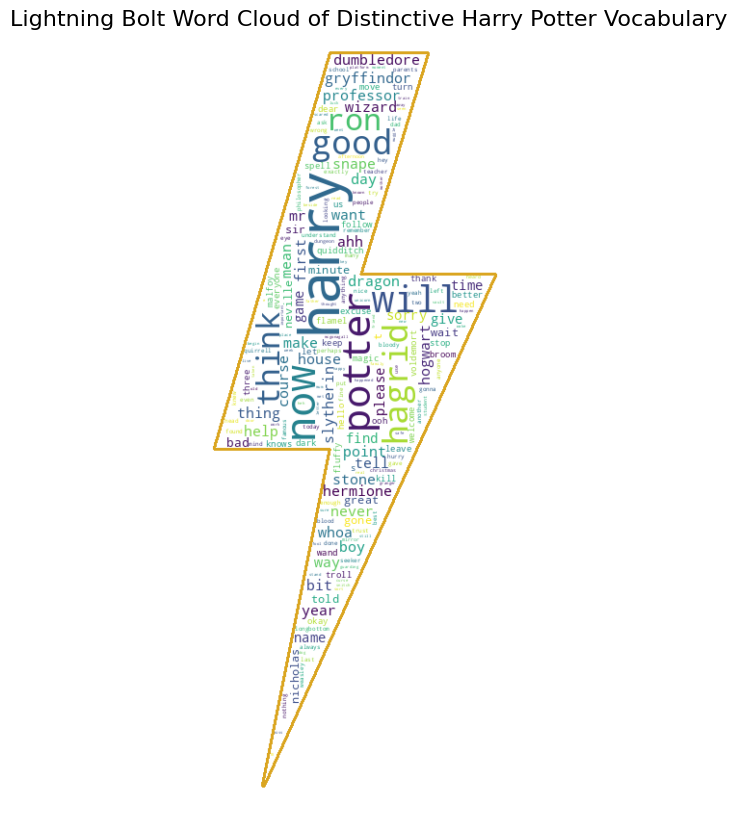

In [9]:
# Combine all dialogue into one corpus.
hp_text = " ".join(hp_dialogue["dialog"].astype(str)).lower()

# Tokenize the text while retaining contractions.
hp_tokens = re.findall(r"[a-z]+(?:['’][a-z]+)*", hp_text)

# Define stopwords to remove common and overly generic words.
custom_stopwords = set(STOPWORDS).union({
    "you", "the", "to", "i", "a", "and", "it", "that", "of", "is",
    "we", "he", "she", "they", "them", "me", "my", "your", "our",
    "this", "there", "here", "oh", "ah", "uh", "well", "know",
    "go", "got", "one", "see", "come", "like", "yes", "no",
    "don't", "can't", "i'm", "that's", "it's", "you're", "we're",
    "would", "could", "said", "say", "get", "going", "back", "right",
    "really", "look", "little", "something", "must", "take"
})

# Keep only the more distinctive words.
distinctive_tokens = [word for word in hp_tokens if word not in custom_stopwords]

# Rejoin into a single string for the word cloud.
distinctive_text = " ".join(distinctive_tokens)

# Create a simple lightning bolt mask.
width, height = 600, 800
mask_image = Image.new("L", (width, height), 255)   # white background
draw = ImageDraw.Draw(mask_image)

# Define the lightning bolt polygon.
bolt_points = [
    (260, 20),
    (360, 20),
    (290, 250),
    (430, 250),
    (190, 780),
    (260, 430),
    (140, 430)
]

# Draw the bolt in black.
draw.polygon(bolt_points, fill=0)

# Convert the mask to a numpy array.
lightning_mask = np.array(mask_image)

# Generate the word cloud.
wc_hp = WordCloud(
    background_color="white",
    max_words=200,
    mask=lightning_mask,
    contour_width=2,
    contour_color="goldenrod",
    collocations=False
).generate(distinctive_text)

# Plot the word cloud.
plt.figure(figsize=(8, 10))
plt.imshow(wc_hp, interpolation="bilinear")
plt.axis("off")
plt.title("Lightning Bolt Word Cloud of Distinctive Harry Potter Vocabulary", fontsize=16)
plt.show()

## Conclusion

The analysis of the dialogue corpus from Harry Potter and the Philosopher's Stone demonstrated how a relatively small proportion of unique words can account for a substantial share of overall word occurrences. Furthermore, the observed frequency distribution exhibited a broadly Zipf-like pattern, whilst the prominence of character names, fictional locations, and magical terminology highlighted how the context of a particular corpus can influence its vocabulary. The additional word-cloud visualization further reinforced these findings, illustrating how text-processing techniques can be utilized to identify and examine linguistic patterns within a familiar work of fiction.

## References:

Bird, S., Klein, E., & Loper, E. (2009). Natural language processing with Python. O'Reilly Media. https://www.nltk.org/book/

Kornflex28. (n.d.). Harry Potter movies dataset [Data set]. GitHub. https://github.com/Kornflex28/hp-dataset